# 11 Regularised linear model, 09:00 cutoff

Notebook 10 showed that the tree models under-forecast when the price level rises and that their gain over the baseline is absent in the last four folds. A linear model with explicit level terms can extrapolate to a level not seen in training. Here: ridge and Huber regression with spline terms for demand, wind and solar (so the non-linearity seen in notebook 03 is available), cyclic splines for time of day, level and profile terms, on the same 17 folds. Results are reported overall and separately for folds 0-12 and 13-16.

## Init

In [1]:
import sys, time
sys.path[:0] = ["notebooks", "."]  # _common imports from repo root or notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, HuberRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler

from _eval import make_folds, score

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

T = pd.read_parquet("outputs/feature_table_dev.parquet")
D9 = T[T["cutoff_hour"] == 9].reset_index(drop=True)
days = pd.DatetimeIndex(sorted(D9["day"].unique()))
folds = make_folds(days, 28, 17, 1)
val_days_all = pd.DatetimeIndex(np.concatenate([f["val_days"].values for f in folds]))
VAL = D9["day"].isin(val_days_all)
print(int(VAL.sum()), "validation rows,", len(folds), "folds")

22847 validation rows, 17 folds


## 1. Model

All preprocessing is fitted on the training rows of each fold only (imputation medians, scaling, spline knots).

- **Splines (cubic, 6 knots, linear extrapolation outside the training range):** forecast demand, Elexon wind, embedded wind, embedded solar.
- **Time of day:** periodic cubic spline on the hour (13 knots, period 24 h).
- **Level and profile terms, standardised:** `med28_same`, `med7_same`, `d2_same`, `level24h`, `level7`, `level28`, `level_gap`. These are linear terms, so a higher level in the inputs moves the forecast up one-for-one (times the fitted coefficient), including beyond the training range.
- **Other:** weekday dummies, bank holiday, seasonal sine/cosine, clock-change flag, the five margin features.
- Missing values (0.6% for demand at 09:00) are filled with the training median. Revision and age features are left out (mostly missing or near-constant).
- **Targets:** direct price, or the deviation `y_dev = price - med28_same` with `med28_same` added back.
- **Estimators:** ridge (squared error) at alpha 1, 30, 300; and Huber regression (robust to the tail) at alpha 1 and 30. The alphas are fixed in advance and all reported.
- Not included: interactions (for example demand x hour); the tree models capture those and this model does not.

In [2]:
SPL = ["demand_mw", "wind_mw", "emb_wind_mw", "emb_solar_mw"]
LVL = ["med28_same", "med7_same", "d2_same", "level24h", "level7", "level28", "level_gap"]
MGN = ["mgn_min_demand", "mgn_surplus", "mgn_constrained", "mgn_gen_avail", "mgn_ic_import"]
OTH = ["bank_holiday", "doy_sin", "doy_cos", "clock_change_day"]
ALL = SPL + LVL + MGN + OTH + ["hour_frac", "weekday"]

def make_pre():
    return ColumnTransformer([
        ("spl", make_pipeline(SimpleImputer(strategy="median"),
                              SplineTransformer(n_knots=6, degree=3, extrapolation="linear"), StandardScaler()), SPL),
        ("hour", SplineTransformer(knots=np.linspace(0, 24, 13).reshape(-1, 1), degree=3, extrapolation="periodic"), ["hour_frac"]),
        ("lvl", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), LVL + MGN),
        ("oth", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), OTH),
        ("wd", OneHotEncoder(handle_unknown="ignore"), ["weekday"]),
    ])

def make_model(kind, alpha):
    est = Ridge(alpha=alpha) if kind == "ridge" else HuberRegressor(alpha=alpha, epsilon=1.35, max_iter=300)
    return Pipeline([("pre", make_pre()), ("est", est)])

def run_cv(kind, alpha, target):
    pred = pd.Series(np.nan, index=D9.index)
    for f in folds:
        ok = D9["price"].notna() & D9["med28_same"].notna()
        tr = D9[D9["day"].isin(f["train_days"]) & ok]
        va = D9[D9["day"].isin(f["val_days"])]
        y = tr["price"] - tr["med28_same"] if target == "dev" else tr["price"]
        m = make_model(kind, alpha).fit(tr[ALL], y)
        p = m.predict(va[ALL])
        pred.loc[va.index] = p + va["med28_same"].to_numpy() if target == "dev" else p
    return pred

def fold_table(pred):
    rows = []
    for f in folds:
        d = D9[D9["day"].isin(f["val_days"])].assign(pred=pred)
        s = score(d, "pred"); s["fold"] = f["fold"]; rows.append(s)
    return pd.DataFrame(rows).set_index("fold")

BASE = fold_table(D9["med28_same"])
old = pd.read_parquet("outputs/cv_preds_gbm_direct_0900.parquet")
GBM = D9[["period_start"]].merge(old[["period_start", "C abs expanding"]], on="period_start", how="left")["C abs expanding"]
GBM.index = D9.index
FT_GBM = fold_table(GBM)
print("ready")

ready


## 2. Run

Ten configurations (2 targets x 5 estimators/alphas).

In [3]:
CFG, FT = {}, {}
t0 = time.time()
for target in ["direct", "dev"]:
    for kind, alphas in [("ridge", [1, 30, 300]), ("huber", [1, 30])]:
        for a in alphas:
            name = f"{kind} a={a} {target}"
            CFG[name] = run_cv(kind, a, target)
            FT[name] = fold_table(CFG[name])
            print(f"{name:22s} {time.time() - t0:5.0f}s")
P = pd.DataFrame(CFG)
for c in ["day", "period_start", "price", "med28_same"]:
    P[c] = D9[c]
P.loc[VAL].to_parquet("outputs/cv_preds_linear_0900.parquet", index=False)

ridge a=1 direct           2s


ridge a=30 direct          3s


ridge a=300 direct         5s


huber a=1 direct          26s


huber a=30 direct         35s


ridge a=1 dev             37s


ridge a=30 dev            38s


ridge a=300 dev           40s


huber a=1 dev             58s


huber a=30 dev            66s


## 3. Scores against the baseline

Mean per-fold difference to the 28-day median (negative is better for MAE and RMSE, positive for the hit rates), over all 17 folds, over folds 0-12, and over folds 13-16. The last column is the mean error in fold 16 (forecast minus actual; negative means under-forecast). The GBM row is the set C model from 07 for reference.

In [4]:
def row(ft):
    d = {m: ft[m] - BASE[m] for m in ["MAE", "RMSE", "hit_top8", "hit_bot8"]}
    r = {}
    for lab, sl in [("all", slice(0, 16)), ("0-12", slice(0, 12)), ("13-16", slice(13, 16))]:
        r[f"dMAE {lab}"] = d["MAE"].loc[sl].mean()
    r["dRMSE all"] = d["RMSE"].mean(); r["dRMSE 13-16"] = d["RMSE"].loc[13:16].mean()
    r["dHitTop all"] = d["hit_top8"].mean(); r["dHitTop 13-16"] = d["hit_top8"].loc[13:16].mean()
    r["dHitBot all"] = d["hit_bot8"].mean(); r["dHitBot 13-16"] = d["hit_bot8"].loc[13:16].mean()
    r["bias f16"] = ft["bias"].loc[16]
    return r
R = pd.DataFrame({"GBM set C direct (07)": row(FT_GBM), **{n: row(ft) for n, ft in FT.items()}}).T
R.loc["baseline bias f16"] = np.nan
R.loc["baseline bias f16", "bias f16"] = BASE["bias"].loc[16]
print(R.round(3).to_string())

                       dMAE all  dMAE 0-12  dMAE 13-16  dRMSE all  dRMSE 13-16  dHitTop all  dHitTop 13-16  dHitBot all  dHitBot 13-16  bias f16
GBM set C direct (07)    -1.716     -2.559       1.023     -3.541       -0.176        0.029          0.023        0.044          0.009   -26.034
ridge a=1 direct          0.169      0.135       0.278      1.576       -1.496       -0.001         -0.020        0.029         -0.000   -17.230
ridge a=30 direct         0.113      0.059       0.288      1.476       -1.481        0.002         -0.019        0.028          0.001   -17.342
ridge a=300 direct       -0.134     -0.269       0.303      0.955       -1.467        0.011         -0.008        0.032         -0.000   -17.665
huber a=1 direct         -1.665     -2.177       0.001     -3.833       -1.445        0.035         -0.002        0.042          0.004   -15.711
huber a=30 direct        -1.871     -2.418      -0.093     -4.152       -1.603        0.036          0.016        0.044          0

## 4. Fold by fold for the two most relevant configurations

Per-fold MAE and mean error for the baseline, the GBM, and the ridge model with alpha 30 on the deviation target and on the direct price.

      base MAE  GBM MAE  ridge a=30 dev MAE  ridge a=30 direct MAE  base bias  GBM bias  ridge a=30 dev bias  ridge a=30 direct bias
fold                                                                                                                                
0         24.9     26.2                27.8                   27.8       -1.0      -7.0                 -7.9                    -7.8
1         36.4     31.7                31.9                   31.9       12.0      12.2                 -2.9                    -2.9
2         40.0     34.4                41.7                   41.7        2.4     -11.3                -25.2                   -25.2
3         25.8     25.1                24.0                   24.0        2.5       6.2                 -5.8                    -5.9
4         27.2     26.2                27.7                   27.7       -2.3      -3.3                 -6.7                    -6.7
5         35.0     30.6                29.7                   29.7   

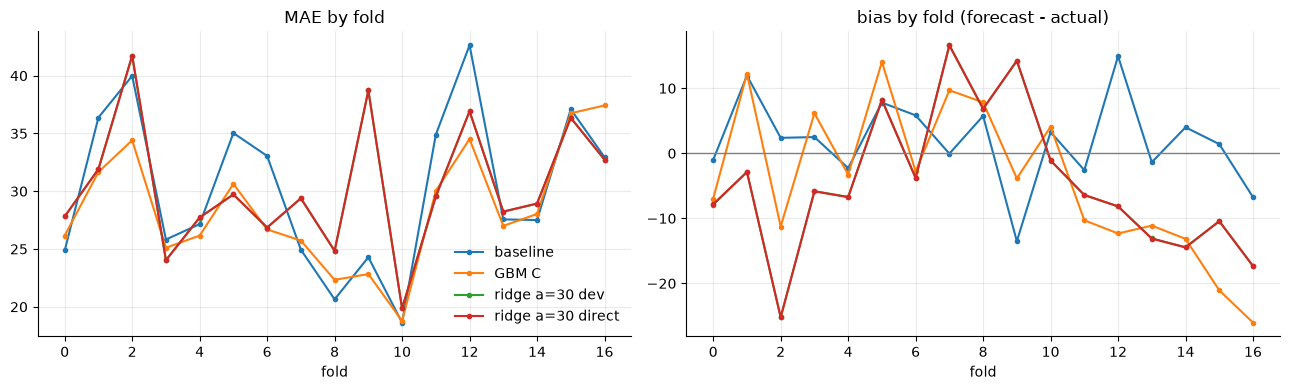

In [5]:
sel = {"ridge a=30 dev": FT["ridge a=30 dev"], "ridge a=30 direct": FT["ridge a=30 direct"]}
tab = pd.DataFrame({"base MAE": BASE["MAE"], "GBM MAE": FT_GBM["MAE"], **{f"{k} MAE": v["MAE"] for k, v in sel.items()},
                    "base bias": BASE["bias"], "GBM bias": FT_GBM["bias"], **{f"{k} bias": v["bias"] for k, v in sel.items()}})
print(tab.round(1).to_string())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for n, ft in [("baseline", BASE), ("GBM C", FT_GBM), ("ridge a=30 dev", FT["ridge a=30 dev"]), ("ridge a=30 direct", FT["ridge a=30 direct"])]:
    axes[0].plot(ft["MAE"], marker="o", ms=3, label=n); axes[1].plot(ft["bias"], marker="o", ms=3, label=n)
axes[0].set_title("MAE by fold"); axes[1].set_title("bias by fold (forecast - actual)")
axes[1].axhline(0, color="grey", lw=1); axes[0].legend(frameon=False)
for ax in axes: ax.set_xlabel("fold")
plt.tight_layout(); plt.show()

## Findings (09:00 cutoff, 17 folds, differences to the 28-day median baseline)

- **Squared-error ridge does not beat the baseline.** MAE +0.1 to +0.2 (alpha 1, 30) or -0.13 to -0.16 (alpha 300); RMSE worse by 1.0 to 1.6; top-8 hit rate unchanged. The deviation and direct targets give the same ridge results to three decimals, as expected: `med28_same` is an input, so the two formulations differ only through the penalty.
- **Robust (Huber) regression is competitive with the gradient boosting model.** Alpha 30: MAE -1.87 (direct) and -1.91 (deviation) over all folds, against -1.72 for the GBM in 07; RMSE -4.1 against -3.5; top-8 hit +0.036/+0.032 and bottom-8 +0.044/+0.049 against +0.029/+0.044. So the demand/wind/solar signal is largely captured by smooth additive effects and does not need trees. The difference between ridge and Huber is the loss: the squared-error fit is evidently distorted by the tail (a possible specific cause is the 2,900 price in early 2025, visible as ridge's large error in fold 9; I have not tested that).
- **Recent folds (13-16): no gain from any linear model either, but less harm than the GBM.** MAE difference to the baseline: Huber -0.09 and -0.24 (alpha 30), GBM +1.02. RMSE: -1.6 to -1.8 against -0.18 for the GBM. Hit-rate gains are small (top-8 +0.01 to +0.02, bottom-8 about 0). So the level of the gain is about zero in the regime closest to the hold-out, with the linear model slightly ahead of the GBM on RMSE.
- **The level problem is not solved.** In fold 16, mean error (forecast minus actual) is -15 to -17 for the linear models, -26 for the GBM and -6.7 for the baseline; in folds 13-15 all models are 10-21 below actual. The explicit level terms did not let the model track the rise. The weather features pull forecasts down (summer demand, solar and wind point to lower prices) while actual prices stayed high, which suggests the price level in a given weather situation has itself moved up (a driver outside this data, such as fuel prices, is a possibility but cannot be tested here).
- **Takeaway.** The weather signal is real and modest; the baseline's recent-level tracking is hard to beat in the highest-price regime. Next candidates: recency weighting; combining the weather effect with the baseline's level through the deviation from a faster-moving level (for example the last 7 days) instead of the 28-day median; and quantile models for the tails. For the hold-out period the most likely result is a small or no gain over the baseline unless the level is handled better.
